# COMP6010 Assignment — Part A: Bayesian-Network Simulation and Sampling Inference

**Student:** Satria Pamungkas &nbsp;|&nbsp; **Student ID:** 21522611 &nbsp;|&nbsp; **Part C option:** C2 (flow matching)

**Scenario — diagnosing an irrigation fault.** A greenhouse operator receives a dry-soil alert and
notices wilting plants. Is the irrigation system faulty, or could hot weather explain the
observations? All probabilities below are the hypothetical teaching values supplied in the
assignment brief, not measurements from a real greenhouse.

Five binary variables ($1$ = true, $0$ = false):

| Symbol | Meaning |
|---|---|
| $H$ | hot weather |
| $F$ | irrigation fault |
| $D$ | dry soil |
| $S$ | soil sensor reports "dry" (may err) |
| $W$ | plants are wilting |

Three diagnostic queries:

$$q_1 = P(F=1 \mid S=1), \qquad q_2 = P(F=1 \mid S=1, W=1), \qquad q_3 = P(F=1 \mid S=1, W=1, H=1)$$

**Contents.** A1 model and exact checks · A2 forward + rejection sampling · A3 likelihood
weighting · A4 comparison and interpretation.

In [1]:
import numpy as np
import pandas as pd
from itertools import product
import matplotlib.pyplot as plt
import json, os, time, platform, sys

# ---------------------------------------------------------------- output paths
def find_results_dir(part="partA"):
    """Resolve <supplement>/results/<part> whether run from notebooks/ or the repo root."""
    here = os.path.abspath(os.getcwd())
    for cand in (os.path.join(here, "..", "results", part),   # run from notebooks/
                 os.path.join(here, "results", part)):        # run from supplement root
        cand = os.path.abspath(cand)
        if os.path.isdir(os.path.dirname(cand)):
            os.makedirs(cand, exist_ok=True)
            return cand
    os.makedirs(os.path.join(here, "results", part), exist_ok=True)
    return os.path.abspath(os.path.join(here, "results", part))

RES = find_results_dir("partA")
print("results ->", RES)

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 150, "display.precision", 5)

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"platform {platform.platform()}")

results -> /home/21522611/Documents/PHUIML-Assignment/Satria_Pamungkas_21522611_COMP6010_Supplement/results/partA
python 3.10.12 | numpy 2.2.6 | pandas 2.3.3
platform Linux-6.8.0-138-generic-x86_64-with-glibc2.35


/home/21522611/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## A1. Represent and check the model  *(2 marks)*

### Directed graph

The brief specifies the edges $H\to D$, $F\to D$, $D\to S$, $D\to W$, $H\to W$:

```
        H ─────────────┐
        │              │            H = hot weather
        │              │            F = irrigation fault
        ▼              ▼            D = dry soil
   ┌──► D ──────────► W             S = sensor reads "dry"
   │    │                           W = plants wilting
   │    │
   F    └──────────► S
```

$H$ and $F$ are the roots and are independent by assumption. $D$ has parents $\{H,F\}$;
$S$ has parent $\{D\}$; $W$ has parents $\{H,D\}$. A valid topological order is
$(H, F, D, S, W)$ — every variable follows its parents.

### Factorisation of the joint distribution

The graph asserts that each variable is conditionally independent of its non-descendants given
its parents, so the joint factorises as one term per node:

$$P(H,F,D,S,W) \;=\; P(H)\,P(F)\,P(D \mid H,F)\,P(S \mid D)\,P(W \mid H,D)$$

This is the product of $2 + 2 + 4 + 2 + 4$ CPT rows rather than the $2^5-1 = 31$ free parameters
of an unconstrained joint over five binary variables — the graph is what buys that reduction.

### A conditional-independence statement implied by the graph

$$S \perp W \mid D, H$$

$S$ depends on the rest of the network only through $D$ (its single parent), so once $D$ is fixed
the sensor reading carries no further information about wilting. Equivalently, $D$ blocks the only
path $S \leftarrow D \rightarrow W$, and the path $S \leftarrow D \leftarrow H \rightarrow W$ is
blocked by conditioning on $H$ as well. A second, simpler example implied by the roots being
independent is $S \perp F \mid D$.

Note that $H$ and $F$ are *marginally* independent but become dependent once $D$ is observed:
$D$ is a collider on the path $H \rightarrow D \leftarrow F$, so observing dry soil creates the
"explaining away" competition between the two causes. This is exactly the effect the three
queries are designed to expose.

In [2]:
# ============================================================ CPTs (from brief)
P_H1 = 0.30          # P(H = 1)
P_F1 = 0.08          # P(F = 1)

# P(D = 1 | H, F) indexed [h][f]
P_D1_given_HF = np.array([[0.05, 0.80],      # H=0: F=0, F=1
                          [0.40, 0.95]])     # H=1: F=0, F=1

# P(S = 1 | D) indexed [d]
P_S1_given_D = np.array([0.10, 0.90])

# P(W = 1 | H, D) indexed [h][d]
P_W1_given_HD = np.array([[0.02, 0.70],      # H=0: D=0, D=1
                          [0.10, 0.90]])     # H=1: D=0, D=1

VARS = ["H", "F", "D", "S", "W"]             # topological order

def bern(p, value):
    """P(X = value) for a Bernoulli with P(X = 1) = p."""
    return p if value == 1 else 1.0 - p

def joint_probability(h, f, d, s, w):
    """P(H=h, F=f, D=d, S=s, W=w) via the factorisation of A1."""
    return (bern(P_H1, h)
            * bern(P_F1, f)
            * bern(P_D1_given_HF[h][f], d)
            * bern(P_S1_given_D[d],     s)
            * bern(P_W1_given_HD[h][d], w))

# ------------------------------------------- enumerate all 2^5 = 32 full states
rows = [dict(H=h, F=f, D=d, S=s, W=w, p=joint_probability(h, f, d, s, w))
        for h, f, d, s, w in product((0, 1), repeat=5)]
joint_df = pd.DataFrame(rows)

total = joint_df["p"].sum()
print(f"number of states enumerated : {len(joint_df)}")
print(f"sum of joint probabilities  : {total!r}")
print(f"deviation from 1            : {abs(total - 1.0):.3e}")
assert np.isclose(total, 1.0, atol=1e-12), "joint does not normalise"
assert (joint_df["p"] >= 0).all(), "negative probability"
print("\nCHECK PASSED: the 32 joint probabilities are non-negative and sum to 1.")
print("\nLargest and smallest states (full table is in the supplement CSV, not the report):")
print(joint_df.sort_values("p", ascending=False).head(3).to_string(index=False))
print(joint_df.sort_values("p").head(2).to_string(index=False))
joint_df.to_csv(os.path.join(RES, "A1_joint_enumeration_32_states.csv"), index=False)

number of states enumerated : 32
sum of joint probabilities  : np.float64(1.0)
deviation from 1            : 0.000e+00

CHECK PASSED: the 32 joint probabilities are non-negative and sum to 1.

Largest and smallest states (full table is in the supplement CSV, not the report):
 H  F  D  S  W       p
 0  0  0  0  0 0.53961
 1  0  0  0  0 0.13414
 1  0  1  1  1 0.08942
 H  F  D  S  W       p
 1  1  0  1  1 0.00001
 0  1  0  1  1 0.00002


In [3]:
# --------------------------------------------- exact inference by enumeration
def exact_conditional(query_var, query_val, evidence):
    """P(query_var = query_val | evidence) by summing the enumerated joint.

    Returns (probability, P(evidence)).  Evidence is a dict like {"S": 1, "W": 1}.
    """
    mask = np.ones(len(joint_df), dtype=bool)
    for var, val in evidence.items():
        mask &= (joint_df[var].values == val)
    p_evidence = joint_df["p"].values[mask].sum()
    if p_evidence == 0.0:
        return float("nan"), 0.0
    mask_q = mask & (joint_df[query_var].values == query_val)
    return joint_df["p"].values[mask_q].sum() / p_evidence, p_evidence

QUERIES = {
    "q1": {"evidence": {"S": 1},                  "label": "P(F=1 | S=1)"},
    "q2": {"evidence": {"S": 1, "W": 1},          "label": "P(F=1 | S=1, W=1)"},
    "q3": {"evidence": {"S": 1, "W": 1, "H": 1},  "label": "P(F=1 | S=1, W=1, H=1)"},
}

exact_rows = []
for key, spec in QUERIES.items():
    val, p_ev = exact_conditional("F", 1, spec["evidence"])
    spec["exact"] = val
    spec["p_evidence"] = p_ev
    exact_rows.append({"query": key, "definition": spec["label"],
                       "exact value": val, "P(evidence)": p_ev,
                       "expected matches per 1,000 samples": 1000 * p_ev})

exact_df = pd.DataFrame(exact_rows)
print("EXACT REFERENCE VALUES (enumeration over all 32 states)\n")
print(exact_df.to_string(index=False))
exact_df.to_csv(os.path.join(RES, "A1_exact_reference_values.csv"), index=False)

EXACT = {k: QUERIES[k]["exact"] for k in QUERIES}
P_EV  = {k: QUERIES[k]["p_evidence"] for k in QUERIES}

EXACT REFERENCE VALUES (enumeration over all 32 states)

query             definition  exact value  P(evidence)  expected matches per 1,000 samples
   q1           P(F=1 | S=1)      0.23150      0.26816                             268.160
   q2      P(F=1 | S=1, W=1)      0.29329      0.15932                             159.316
   q3 P(F=1 | S=1, W=1, H=1)      0.16867      0.10956                             109.560


In [4]:
# Independent structural checks that would catch a transposed CPT lookup.
# 1. Marginal of a root must return its own CPT value.
p_H1 = joint_df.loc[joint_df.H == 1, "p"].sum()
p_F1 = joint_df.loc[joint_df.F == 1, "p"].sum()
print(f"marginal P(H=1) = {p_H1:.6f}   (CPT says {P_H1})")
print(f"marginal P(F=1) = {p_F1:.6f}   (CPT says {P_F1})")

# 2. H and F must be independent a priori, but dependent given D (collider).
p_H1F1 = joint_df.loc[(joint_df.H == 1) & (joint_df.F == 1), "p"].sum()
print(f"\nP(H=1,F=1) = {p_H1F1:.6f} vs P(H=1)P(F=1) = {p_H1 * p_F1:.6f}  -> independent")
p_F1_D1, _ = exact_conditional("F", 1, {"D": 1})
p_F1_D1H1, _ = exact_conditional("F", 1, {"D": 1, "H": 1})
print(f"P(F=1|D=1)     = {p_F1_D1:.6f}")
print(f"P(F=1|D=1,H=1) = {p_F1_D1H1:.6f}  -> lower: hot weather explains away the fault")

# 3. The claimed conditional independence S _||_ W | D, H must hold numerically.
worst = 0.0
for h, d in product((0, 1), repeat=2):
    for s, w in product((0, 1), repeat=2):
        p_sw, _ = exact_conditional("S", s, {"D": d, "H": h, "W": w})
        p_s,  _ = exact_conditional("S", s, {"D": d, "H": h})
        worst = max(worst, abs(p_sw - p_s))
print(f"\nmax |P(S=s|D,H,W) - P(S=s|D,H)| over all settings = {worst:.3e}  -> S _||_ W | D,H holds")

# 4. A deliberately transposed CPT lookup changes the answer -> the test has power.
def joint_transposed(h, f, d, s, w):
    return (bern(P_H1, h) * bern(P_F1, f)
            * bern(P_D1_given_HF[f][h], d)       # BUG: indices swapped
            * bern(P_S1_given_D[d], s) * bern(P_W1_given_HD[h][d], w))
bad = sum(joint_transposed(*st) for st in product((0, 1), repeat=5))
bad_q1 = (sum(joint_transposed(h, 1, d, 1, w) for h, d, w in product((0, 1), repeat=3))
          / sum(joint_transposed(h, f, d, 1, w) for h, f, d, w in product((0, 1), repeat=4)))
print(f"\nwith H,F swapped in the D lookup: sum = {bad:.6f} (still 1, so normalisation alone "
      f"would NOT detect it)\n  but q1 becomes {bad_q1:.5f} instead of {EXACT['q1']:.5f} "
      "-> the query check does detect it.")

marginal P(H=1) = 0.300000   (CPT says 0.3)
marginal P(F=1) = 0.080000   (CPT says 0.08)

P(H=1,F=1) = 0.024000 vs P(H=1)P(F=1) = 0.024000  -> independent
P(F=1|D=1)     = 0.321598
P(F=1|D=1,H=1) = 0.171171  -> lower: hot weather explains away the fault

max |P(S=s|D,H,W) - P(S=s|D,H)| over all settings = 2.220e-16  -> S _||_ W | D,H holds

with H,F swapped in the D lookup: sum = 1.000000 (still 1, so normalisation alone would NOT detect it)
  but q1 becomes 0.13043 instead of 0.23150 -> the query check does detect it.


## A2. Forward sampling and rejection-based inference  *(3 marks)*

### How a uniform random number and a CPT entry generate a binary value

To sample a binary variable $X$ with $P(X=1 \mid \text{parents}) = p$, draw $u \sim \mathrm{Uniform}[0,1)$ and set

$$x = \mathbb{1}[u < p] \quad\Longrightarrow\quad P(x=1) = P(u < p) = p$$

because the uniform CDF is $F(u)=u$ on $[0,1]$. This is inverse-CDF sampling specialised to two
outcomes: the interval $[0,1)$ is cut at $p$, and the sub-interval widths *are* the two
probabilities. The correct CPT row must be selected first using the values already sampled for the
parents — which is why the loop must follow a topological order.

### Forward (ancestral) sampling

Visit $(H, F, D, S, W)$ in topological order; each variable's parents are already assigned, so the
required CPT row is always available. The resulting full assignments are i.i.d. draws from the
exact joint $P(H,F,D,S,W)$ — no evidence is used at this stage.

### Rejection sampling

To estimate $P(F=1 \mid e)$: generate joint samples, **discard** every sample inconsistent with the
evidence $e$, and take the fraction of the retained samples that have $F=1$:

$$\hat{P}(F=1 \mid e) = \frac{\#\{\text{samples with } F=1 \text{ and } e\}}{\#\{\text{samples with } e\}}$$

This is valid because conditioning on an event and restricting the sample to that event are the
same operation. Its cost is that the retained fraction is $P(e)$, so rare evidence wastes almost
every sample. If **no** sample matches the evidence the estimate is undefined ($0/0$) and is
reported as `NaN` — not as $0$ or any other invented value.

One joint sample set is generated per seed and reused for all three queries, as the brief permits.

In [5]:
def forward_sample(rng):
    """One ancestral sample from P(H,F,D,S,W). Returns dict of 0/1 values.

    Written out longhand to show the uniform-vs-CPT comparison for each variable.
    """
    h = int(rng.random() < P_H1)                      # root
    f = int(rng.random() < P_F1)                      # root, independent of h
    d = int(rng.random() < P_D1_given_HF[h][f])       # needs h, f -> already sampled
    s = int(rng.random() < P_S1_given_D[d])           # needs d
    w = int(rng.random() < P_W1_given_HD[h][d])       # needs h, d
    return {"H": h, "F": f, "D": d, "S": s, "W": w}

def forward_sample_batch(n, rng):
    """Vectorised equivalent of n forward_sample() calls -> (n, 5) int array, cols = VARS.

    Same inverse-CDF rule, applied to whole columns; parents are sampled before children so the
    CPT lookup uses the already-drawn parent values (fancy indexing does the row selection).
    """
    H = (rng.random(n) < P_H1).astype(np.int8)
    F = (rng.random(n) < P_F1).astype(np.int8)
    D = (rng.random(n) < P_D1_given_HF[H, F]).astype(np.int8)
    S = (rng.random(n) < P_S1_given_D[D]).astype(np.int8)
    W = (rng.random(n) < P_W1_given_HD[H, D]).astype(np.int8)
    return np.column_stack([H, F, D, S, W])

# --- verify the vectorised version agrees in distribution with the scalar version, and that
# --- both reproduce the exact marginals (a wrong parent lookup would show up here).
rng_chk = np.random.default_rng(0)
big = forward_sample_batch(400_000, rng_chk)
emp = big.mean(axis=0)
ex_marg = [joint_df.loc[joint_df[v] == 1, "p"].sum() for v in VARS]
print("variable   empirical(400k)      exact     abs diff")
for v, e, x in zip(VARS, emp, ex_marg):
    print(f"   {v}         {e:.5f}         {x:.5f}     {abs(e - x):.5f}")
scalar = np.array([[forward_sample(np.random.default_rng(7 + i))[v] for v in VARS]
                   for i in range(20_000)])
print(f"\nscalar-loop marginals over 20k samples: "
      f"{np.round(scalar.mean(axis=0), 4).tolist()}  (same pattern)")

variable   empirical(400k)      exact     abs diff
   H         0.29997         0.30000     0.00003
   F         0.07995         0.08000     0.00005
   D         0.21007         0.21020     0.00013
   S         0.26778         0.26816     0.00038
   W         0.20328         0.20292     0.00036



scalar-loop marginals over 20k samples: [0.3046, 0.0819, 0.2122, 0.2708, 0.2064]  (same pattern)


In [6]:
IDX = {v: i for i, v in enumerate(VARS)}

def rejection_estimate(samples, evidence, query_var="F", query_val=1):
    """Rejection-sampling estimate from a pre-generated joint sample array.

    Returns (estimate, n_retained). estimate is NaN when nothing matches the evidence.
    """
    mask = np.ones(len(samples), dtype=bool)
    for var, val in evidence.items():
        mask &= samples[:, IDX[var]] == val
    n_ret = int(mask.sum())
    if n_ret == 0:
        return float("nan"), 0                       # undefined, not invented
    est = float((samples[mask, IDX[query_var]] == query_val).mean())
    return est, n_ret

SAMPLE_SIZES = [1_000, 10_000, 100_000]
SEEDS = [11, 22, 33, 44, 55]                         # five independent seeds per size

rej_records = []
for N in SAMPLE_SIZES:
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        t0 = time.perf_counter()
        samples = forward_sample_batch(N, rng)       # ONE sample set reused by all 3 queries
        t_gen = time.perf_counter() - t0
        for key, spec in QUERIES.items():
            t1 = time.perf_counter()
            est, n_ret = rejection_estimate(samples, spec["evidence"])
            t_q = time.perf_counter() - t1
            rej_records.append({
                "method": "rejection", "query": key, "N": N, "seed": seed,
                "estimate": est, "n_retained": n_ret,
                "retained_fraction": n_ret / N,
                "exact": EXACT[key],
                "abs_error": abs(est - EXACT[key]) if np.isfinite(est) else np.nan,
                "gen_time_s": t_gen, "query_time_s": t_q,
            })

rej_df = pd.DataFrame(rej_records)
rej_df.to_csv(os.path.join(RES, "A2_rejection_per_run.csv"), index=False)

print("REJECTION SAMPLING — per-run detail (full table also saved to the supplement)\n")
for key in QUERIES:
    sub = rej_df[rej_df["query"] == key]
    print(f"--- {key}: {QUERIES[key]['label']}   exact = {EXACT[key]:.5f} ---")
    print(sub[["N", "seed", "estimate", "n_retained", "retained_fraction", "abs_error"]]
          .to_string(index=False))
    print()

REJECTION SAMPLING — per-run detail (full table also saved to the supplement)

--- q1: P(F=1 | S=1)   exact = 0.23150 ---
     N  seed  estimate  n_retained  retained_fraction  abs_error
  1000    11   0.25692         253            0.25300    0.02541
  1000    22   0.22183         284            0.28400    0.00967
  1000    33   0.24373         279            0.27900    0.01222
  1000    44   0.24125         257            0.25700    0.00974
  1000    55   0.22662         278            0.27800    0.00488
 10000    11   0.22669        2638            0.26380    0.00482
 10000    22   0.23259        2657            0.26570    0.00109
 10000    33   0.21660        2687            0.26870    0.01491
 10000    44   0.23254        2649            0.26490    0.00104
 10000    55   0.23201        2612            0.26120    0.00050
100000    11   0.22773       26610            0.26610    0.00377
100000    22   0.22955       26853            0.26853    0.00196
100000    33   0.23077       2695

In [7]:
undef = rej_df[~np.isfinite(rej_df["estimate"])]
print(f"undefined (NaN) rejection estimates: {len(undef)} of {len(rej_df)}")
if len(undef):
    print(undef[["query", "N", "seed", "n_retained"]].to_string(index=False))

print("\nRetained samples vs the exact evidence probability:")
summary_ret = (rej_df.groupby(["query", "N"])
               .agg(mean_retained=("n_retained", "mean"),
                    mean_fraction=("retained_fraction", "mean"))
               .reset_index())
summary_ret["exact_P_evidence"] = summary_ret["query"].map(P_EV)
print(summary_ret.to_string(index=False))
print("\nThe retained fraction tracks P(evidence): the more evidence variables are added, the "
      "smaller the usable sample and the noisier the estimate at fixed N.")

undefined (NaN) rejection estimates: 0 of 45

Retained samples vs the exact evidence probability:
query      N  mean_retained  mean_fraction  exact_P_evidence
   q1   1000          270.2        0.27020           0.26816
   q1  10000         2648.6        0.26486           0.26816
   q1 100000        26784.8        0.26785           0.26816
   q2   1000          162.6        0.16260           0.15932
   q2  10000         1575.4        0.15754           0.15932
   q2 100000        15897.4        0.15897           0.15932
   q3   1000          113.0        0.11300           0.10956
   q3  10000         1094.8        0.10948           0.10956
   q3 100000        10944.0        0.10944           0.10956

The retained fraction tracks P(evidence): the more evidence variables are added, the smaller the usable sample and the noisier the estimate at fixed N.


## A3. Likelihood weighting  *(3 marks)*

I implement **likelihood weighting** only, as recommended by the brief (implementing Gibbs as well
purely to add code would not earn extra marks).

### The estimator

Evidence variables are **clamped** to their observed values instead of being sampled; the remaining
variables are sampled from their CPTs in topological order, exactly as in forward sampling. Because
the evidence was forced rather than drawn, each sample is a draw from the wrong distribution
$Q$, and must be re-weighted by the likelihood of the evidence it was forced into:

$$w \;=\; \prod_{E_i \in \mathcal{E}} P\!\left(E_i = e_i \mid \mathrm{parents}(E_i)\right)$$

where the parent values are the ones sampled for that particular sample. The estimator is a
weighted average:

$$\hat{P}(F=1 \mid e) \;=\; \frac{\sum_{k:\, F^{(k)}=1} w^{(k)}}{\sum_k w^{(k)}}$$

### Why weighted counts rather than unweighted counts are required

Sampling the non-evidence variables and clamping the evidence draws from the **mutilated** network
$Q(x_{-\mathcal{E}}) = \prod_{X_i \notin \mathcal{E}} P(x_i \mid \mathrm{pa}_i)$, not from the
posterior $P(x_{-\mathcal{E}} \mid e)$. Writing the true target as

$$P(x_{-\mathcal{E}} \mid e) \;=\; \frac{P(x_{-\mathcal{E}}, e)}{P(e)} \;=\; \frac{Q(x_{-\mathcal{E}})\; w(x_{-\mathcal{E}})}{P(e)}$$

shows that $w$ is exactly the importance ratio $P(x_{-\mathcal{E}},e)/Q(x_{-\mathcal{E}})$. So
$\mathbb{E}_Q[w \cdot \mathbb{1}(F=1)] = P(F=1, e)$ and $\mathbb{E}_Q[w] = P(e)$; their ratio is the
required conditional. If the samples were counted **unweighted**, we would instead be computing
$Q(F=1)$, which for this network is just the prior $P(F=1)=0.08$ — the sensor and wilting evidence
would be ignored entirely, because clamping a *downstream* variable has no effect on how its
*ancestors* are sampled. The weights are what propagate the evidence backwards up the graph.

### Normalisation

The denominator $\sum_k w^{(k)}$ is a Monte-Carlo estimate of $P(e)$ and is generally not $N$, so
dividing by $N$ instead of by $\sum_k w^{(k)}$ would give the *joint* $P(F=1,e)$ rather than the
conditional. Every sample is retained (no rejection), but samples with small weights contribute
almost nothing, which is the mechanism behind the effective-sample-size diagnostic below.

Note that $H$ in $q_3$ is a **root** evidence variable, so its contribution to the weight is the
constant $P(H=1)=0.30$; only non-root evidence ($S$, $W$) makes the weights vary.

In [8]:
def likelihood_weighted_sample(evidence, rng):
    """One likelihood-weighted sample. Returns (assignment dict, weight).

    Non-evidence variables are sampled from their CPTs in topological order; evidence variables
    are clamped and multiply the weight by the likelihood of their observed value.
    """
    x, w = {}, 1.0

    # H (root)
    if "H" in evidence:
        x["H"] = evidence["H"];  w *= bern(P_H1, x["H"])
    else:
        x["H"] = int(rng.random() < P_H1)

    # F (root)
    if "F" in evidence:
        x["F"] = evidence["F"];  w *= bern(P_F1, x["F"])
    else:
        x["F"] = int(rng.random() < P_F1)

    # D | H, F
    p_d = P_D1_given_HF[x["H"]][x["F"]]
    if "D" in evidence:
        x["D"] = evidence["D"];  w *= bern(p_d, x["D"])
    else:
        x["D"] = int(rng.random() < p_d)

    # S | D
    p_s = P_S1_given_D[x["D"]]
    if "S" in evidence:
        x["S"] = evidence["S"];  w *= bern(p_s, x["S"])
    else:
        x["S"] = int(rng.random() < p_s)

    # W | H, D
    p_w = P_W1_given_HD[x["H"]][x["D"]]
    if "W" in evidence:
        x["W"] = evidence["W"];  w *= bern(p_w, x["W"])
    else:
        x["W"] = int(rng.random() < p_w)

    return x, w

def lw_batch(evidence, n, rng):
    """Vectorised likelihood weighting -> (samples (n,5), weights (n,)). Same rule as above."""
    w = np.ones(n)
    if "H" in evidence:
        H = np.full(n, evidence["H"], dtype=np.int8); w *= np.where(H == 1, P_H1, 1 - P_H1)
    else:
        H = (rng.random(n) < P_H1).astype(np.int8)
    if "F" in evidence:
        F = np.full(n, evidence["F"], dtype=np.int8); w *= np.where(F == 1, P_F1, 1 - P_F1)
    else:
        F = (rng.random(n) < P_F1).astype(np.int8)
    p_d = P_D1_given_HF[H, F]
    if "D" in evidence:
        D = np.full(n, evidence["D"], dtype=np.int8); w *= np.where(D == 1, p_d, 1 - p_d)
    else:
        D = (rng.random(n) < p_d).astype(np.int8)
    p_s = P_S1_given_D[D]
    if "S" in evidence:
        S = np.full(n, evidence["S"], dtype=np.int8); w *= np.where(S == 1, p_s, 1 - p_s)
    else:
        S = (rng.random(n) < p_s).astype(np.int8)
    p_w = P_W1_given_HD[H, D]
    if "W" in evidence:
        W = np.full(n, evidence["W"], dtype=np.int8); w *= np.where(W == 1, p_w, 1 - p_w)
    else:
        W = (rng.random(n) < p_w).astype(np.int8)
    return np.column_stack([H, F, D, S, W]), w

def lw_estimate(samples, weights, query_var="F", query_val=1):
    """Weighted estimate  sum(w | F=1) / sum(w).  NaN if all weights vanish."""
    denom = weights.sum()
    if denom <= 0:
        return float("nan")
    num = weights[samples[:, IDX[query_var]] == query_val].sum()
    return float(num / denom)

# agreement check between the scalar reference implementation and the vectorised one
rng_a = np.random.default_rng(123)
sc = [likelihood_weighted_sample({"S": 1, "W": 1}, rng_a) for _ in range(30_000)]
sc_s = np.array([[d[v] for v in VARS] for d, _ in sc]); sc_w = np.array([w for _, w in sc])
rng_b = np.random.default_rng(456)
vc_s, vc_w = lw_batch({"S": 1, "W": 1}, 30_000, rng_b)
print(f"q2 exact                     = {EXACT['q2']:.5f}")
print(f"scalar likelihood weighting  = {lw_estimate(sc_s, sc_w):.5f}")
print(f"vectorised likelihood weight = {lw_estimate(vc_s, vc_w):.5f}")
print(f"\nmean weight (scalar) = {sc_w.mean():.5f}  vs exact P(S=1,W=1) = {P_EV['q2']:.5f}"
      "   <- the mean weight estimates P(evidence)")

q2 exact                     = 0.29329
scalar likelihood weighting  = 0.29068
vectorised likelihood weight = 0.28884

mean weight (scalar) = 0.15711  vs exact P(S=1,W=1) = 0.15932   <- the mean weight estimates P(evidence)


In [9]:
# Demonstration of why UNWEIGHTED counts fail: they ignore the evidence completely.
rng_d = np.random.default_rng(2024)
s_demo, w_demo = lw_batch({"S": 1, "W": 1}, 200_000, rng_d)
unweighted = float((s_demo[:, IDX["F"]] == 1).mean())
weighted   = lw_estimate(s_demo, w_demo)
print(f"unweighted fraction of samples with F=1 : {unweighted:.5f}   (prior P(F=1) = {P_F1})")
print(f"weighted estimate                       : {weighted:.5f}   (exact = {EXACT['q2']:.5f})")
print("\nClamping S and W does not change how their ancestors H, F, D are drawn, so the "
      "unweighted count recovers only the prior. The weights carry the evidence.")

unweighted fraction of samples with F=1 : 0.08002   (prior P(F=1) = 0.08)
weighted estimate                       : 0.29375   (exact = 0.29329)

Clamping S and W does not change how their ancestors H, F, D are drawn, so the unweighted count recovers only the prior. The weights carry the evidence.


In [10]:
lw_records = []
for N in SAMPLE_SIZES:
    for seed in SEEDS:
        for key, spec in QUERIES.items():
            rng = np.random.default_rng(seed * 1000 + len(spec["evidence"]))
            t0 = time.perf_counter()
            s, w = lw_batch(spec["evidence"], N, rng)
            est = lw_estimate(s, w)
            t_tot = time.perf_counter() - t0
            sw, sw2 = w.sum(), (w ** 2).sum()
            ess = (sw ** 2 / sw2) if sw2 > 0 else 0.0      # Kish effective sample size
            lw_records.append({
                "method": "likelihood_weighting", "query": key, "N": N, "seed": seed,
                "estimate": est, "exact": EXACT[key],
                "abs_error": abs(est - EXACT[key]) if np.isfinite(est) else np.nan,
                "sum_w": sw, "mean_w": w.mean(), "max_w": w.max(),
                "ess": ess, "ess_fraction": ess / N,
                "top1pct_weight_share": float(np.sort(w)[-max(1, N // 100):].sum() / sw),
                "n_retained": N,                            # every sample is used
                "retained_fraction": 1.0,
                "total_time_s": t_tot,
            })

lw_df = pd.DataFrame(lw_records)
lw_df.to_csv(os.path.join(RES, "A3_likelihood_weighting_per_run.csv"), index=False)

for key in QUERIES:
    sub = lw_df[lw_df["query"] == key]
    print(f"--- {key}: {QUERIES[key]['label']}   exact = {EXACT[key]:.5f} ---")
    print(sub[["N", "seed", "estimate", "abs_error", "mean_w", "max_w",
               "ess", "ess_fraction", "top1pct_weight_share"]].to_string(index=False))
    print()

--- q1: P(F=1 | S=1)   exact = 0.23150 ---
     N  seed  estimate  abs_error  mean_w  max_w         ess  ess_fraction  top1pct_weight_share
  1000    11   0.26894    0.03744 0.26400    0.9   400.55172       0.40055               0.03409
  1000    22   0.20727    0.02423 0.28320    0.9   415.12547       0.41513               0.03178
  1000    33   0.30605    0.07454 0.27120    0.9   405.90199       0.40590               0.03319
  1000    44   0.21777    0.01374 0.25440    0.9   393.67007       0.39367               0.03538
  1000    55   0.25599    0.02449 0.25040    0.9   390.89875       0.39090               0.03594
 10000    11   0.22034    0.01116 0.27208    0.9  4065.65940       0.40657               0.03308
 10000    22   0.21500    0.01650 0.26744    0.9  4030.89234       0.40309               0.03365
 10000    33   0.23684    0.00533 0.26440    0.9  4008.44954       0.40084               0.03404
 10000    44   0.22713    0.00437 0.26496    0.9  4012.56296       0.40126          

WEIGHT CONCENTRATION (mean over the five seeds at N = 100,000)

query  mean_weight  max_weight         ESS  ESS_fraction  top_1pct_share  exact_P_evidence
   q1      0.26795       0.900 40347.16192       0.40347         0.03359           0.26816
   q2      0.16000       0.810 21598.03611       0.21598         0.05063           0.15932
   q3      0.10965       0.243 45811.75947       0.45812         0.02216           0.10956


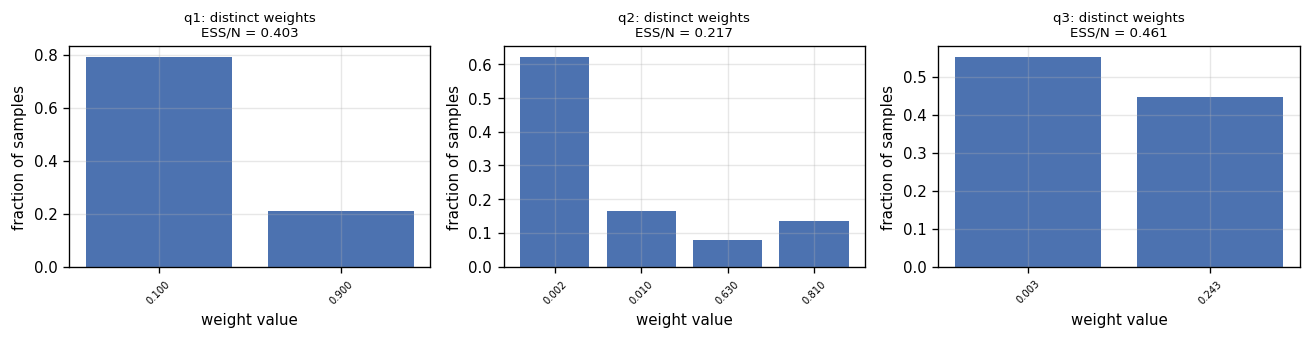


The weight takes only a few distinct values here (the evidence CPT entries are discrete), so no single sample dominates -- ESS/N stays close to the mean weight rather than collapsing. This network is small and its evidence is not extreme; in larger networks with many evidence nodes the product of likelihoods can concentrate on a handful of samples.


In [11]:
# Weight-concentration diagnostic: do a few weights dominate?
print("WEIGHT CONCENTRATION (mean over the five seeds at N = 100,000)\n")
conc = (lw_df[lw_df.N == 100_000].groupby("query")
        .agg(mean_weight=("mean_w", "mean"), max_weight=("max_w", "mean"),
             ESS=("ess", "mean"), ESS_fraction=("ess_fraction", "mean"),
             top_1pct_share=("top1pct_weight_share", "mean")).reset_index())
conc["exact_P_evidence"] = conc["query"].map(P_EV)
print(conc.to_string(index=False))

rng_h = np.random.default_rng(99)
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9))
for ax, (key, spec) in zip(axes, QUERIES.items()):
    _, w = lw_batch(spec["evidence"], 100_000, rng_h)
    uniq, counts = np.unique(np.round(w, 10), return_counts=True)
    ax.bar(range(len(uniq)), counts / counts.sum(), color="#4C72B0")
    ax.set_xticks(range(len(uniq)))
    ax.set_xticklabels([f"{u:.3f}" for u in uniq], rotation=45, fontsize=6)
    ax.set_title(f"{key}: distinct weights\nESS/N = {(w.sum()**2/(w**2).sum())/100_000:.3f}",
                 fontsize=8)
    ax.set_xlabel("weight value"); ax.set_ylabel("fraction of samples")
plt.tight_layout()
plt.savefig(os.path.join(RES, "A3_weight_distribution.png"), bbox_inches="tight")
plt.show()
print("\nThe weight takes only a few distinct values here (the evidence CPT entries are "
      "discrete), so no single sample dominates -- ESS/N stays close to the mean weight rather "
      "than collapsing. This network is small and its evidence is not extreme; in larger networks "
      "with many evidence nodes the product of likelihoods can concentrate on a handful of samples.")

## A4. Compare and interpret  *(2 marks)*

In [12]:
all_df = pd.concat([rej_df, lw_df], ignore_index=True, sort=False)
all_df.to_csv(os.path.join(RES, "A4_all_runs_combined.csv"), index=False)

def agg(g):
    e = g["estimate"]
    return pd.Series({
        "n_defined": int(np.isfinite(e).sum()),
        "mean_estimate": e.mean(skipna=True),
        "std_estimate": e.std(skipna=True, ddof=1),
        "mean_abs_error": g["abs_error"].mean(skipna=True),
        "mean_retained": g["n_retained"].mean(),
        "mean_retained_frac": g["retained_fraction"].mean(),
    })

summary = (all_df.groupby(["query", "method", "N"], as_index=False)
           .apply(agg, include_groups=False).reset_index(drop=True))
summary["exact"] = summary["query"].map(EXACT)
summary = summary[["query", "exact", "method", "N", "n_defined", "mean_estimate",
                   "std_estimate", "mean_abs_error", "mean_retained", "mean_retained_frac"]]
summary.to_csv(os.path.join(RES, "A4_summary_table.csv"), index=False)

print("SUMMARY OVER FIVE SEEDS — mean estimate, standard deviation, mean absolute error\n")
for key in QUERIES:
    print(f"### {key} = {QUERIES[key]['label']}   exact = {EXACT[key]:.5f}")
    print(summary[summary["query"] == key].drop(columns=["query", "exact"]).to_string(index=False))
    print()

SUMMARY OVER FIVE SEEDS — mean estimate, standard deviation, mean absolute error

### q1 = P(F=1 | S=1)   exact = 0.23150
              method      N  n_defined  mean_estimate  std_estimate  mean_abs_error  mean_retained  mean_retained_frac
likelihood_weighting   1000        5.0        0.25120       0.03998         0.03489         1000.0             1.00000
likelihood_weighting  10000        5.0        0.22695       0.00944         0.00826        10000.0             1.00000
likelihood_weighting 100000        5.0        0.23120       0.00152         0.00127       100000.0             1.00000
           rejection   1000        5.0        0.23807       0.01407         0.01239          270.2             0.27020
           rejection  10000        5.0        0.22809       0.00688         0.00447         2648.6             0.26486
           rejection 100000        5.0        0.23088       0.00266         0.00199        26784.8             0.26785

### q2 = P(F=1 | S=1, W=1)   exact = 0.29329

In [13]:
# Compact report table: mean +- sd per query / method / N
compact = summary.copy()
compact["estimate (mean +/- sd)"] = [
    f"{m:.4f} +/- {s:.4f}" if np.isfinite(m) else "undefined"
    for m, s in zip(compact["mean_estimate"], compact["std_estimate"])]
compact["MAE"] = compact["mean_abs_error"].map(lambda v: f"{v:.4f}")
compact["method"] = compact["method"].map({"rejection": "Rejection",
                                           "likelihood_weighting": "Likelihood wt."})
tbl = compact.pivot_table(index=["query", "exact", "N"], columns="method",
                          values="estimate (mean +/- sd)", aggfunc="first")
mae = compact.pivot_table(index=["query", "exact", "N"], columns="method",
                          values="MAE", aggfunc="first")
report_tbl = tbl.join(mae, lsuffix=" est", rsuffix=" MAE").reset_index()
print("COMPACT TABLE FOR THE REPORT\n")
print(report_tbl.to_string(index=False))
report_tbl.to_csv(os.path.join(RES, "A4_report_table.csv"), index=False)
with open(os.path.join(RES, "A4_report_table.md"), "w") as f:
    f.write(report_tbl.to_markdown(index=False))

COMPACT TABLE FOR THE REPORT

query   exact      N Likelihood wt. est     Rejection est Likelihood wt. MAE Rejection MAE
   q1 0.23150   1000  0.2512 +/- 0.0400 0.2381 +/- 0.0141             0.0349        0.0124
   q1 0.23150  10000  0.2269 +/- 0.0094 0.2281 +/- 0.0069             0.0083        0.0045
   q1 0.23150 100000  0.2312 +/- 0.0015 0.2309 +/- 0.0027             0.0013        0.0020
   q2 0.29329   1000  0.3065 +/- 0.0227 0.2941 +/- 0.0111             0.0220        0.0078
   q2 0.29329  10000  0.2846 +/- 0.0118 0.2845 +/- 0.0077             0.0099        0.0087
   q2 0.29329 100000  0.2939 +/- 0.0026 0.2933 +/- 0.0050             0.0022        0.0040
   q3 0.16867   1000  0.1726 +/- 0.0160 0.1696 +/- 0.0188             0.0135        0.0136
   q3 0.16867  10000  0.1670 +/- 0.0040 0.1608 +/- 0.0176             0.0029        0.0149
   q3 0.16867 100000  0.1688 +/- 0.0015 0.1688 +/- 0.0051             0.0010        0.0043


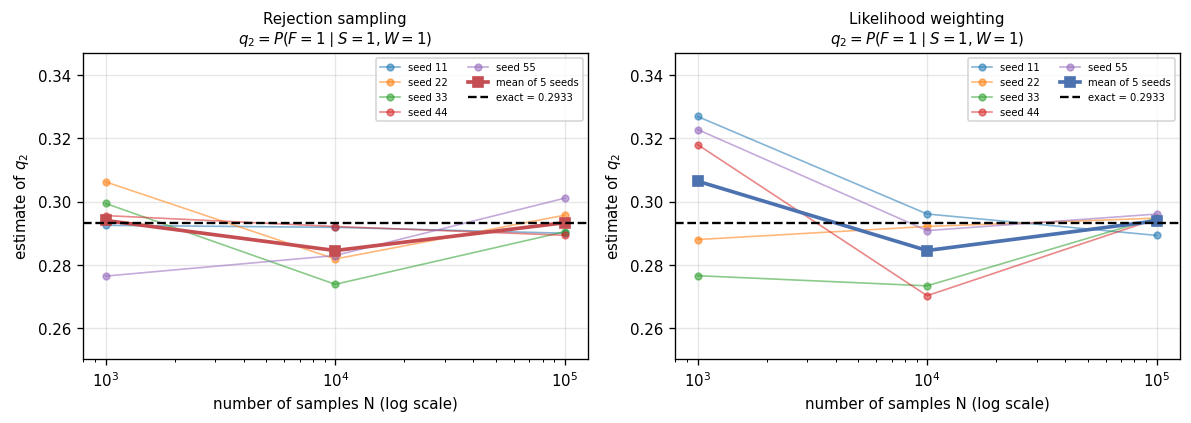

In [14]:
# ------------------------------------- convergence plot for q2 with the exact value shown
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, (meth, mlabel, colour) in zip(
        axes, [("rejection", "Rejection sampling", "#C44E52"),
               ("likelihood_weighting", "Likelihood weighting", "#4C72B0")]):
    sub = all_df[(all_df["query"] == "q2") & (all_df["method"] == meth)]
    for seed in SEEDS:
        ss = sub[sub.seed == seed].sort_values("N")
        ax.plot(ss["N"], ss["estimate"], marker="o", ms=4, lw=1, alpha=0.55,
                label=f"seed {seed}")
    m = sub.groupby("N")["estimate"].mean()
    ax.plot(m.index, m.values, color=colour, lw=2.2, marker="s", ms=6,
            label="mean of 5 seeds")
    ax.axhline(EXACT["q2"], color="black", ls="--", lw=1.4,
               label=f"exact = {EXACT['q2']:.4f}")
    ax.set_xscale("log")
    ax.set_xlabel("number of samples N (log scale)")
    ax.set_ylabel("estimate of $q_2$")
    ax.set_title(mlabel + "\n$q_2 = P(F{=}1 \\mid S{=}1, W{=}1)$", fontsize=9)
    ax.legend(fontsize=6, ncol=2)

lo = min(all_df[all_df["query"] == "q2"]["estimate"].min(), EXACT["q2"]) - 0.02
hi = max(all_df[all_df["query"] == "q2"]["estimate"].max(), EXACT["q2"]) + 0.02
for ax in axes:
    ax.set_ylim(lo, hi)
plt.tight_layout()
plt.savefig(os.path.join(RES, "A4_convergence_q2.png"), bbox_inches="tight")
plt.show()

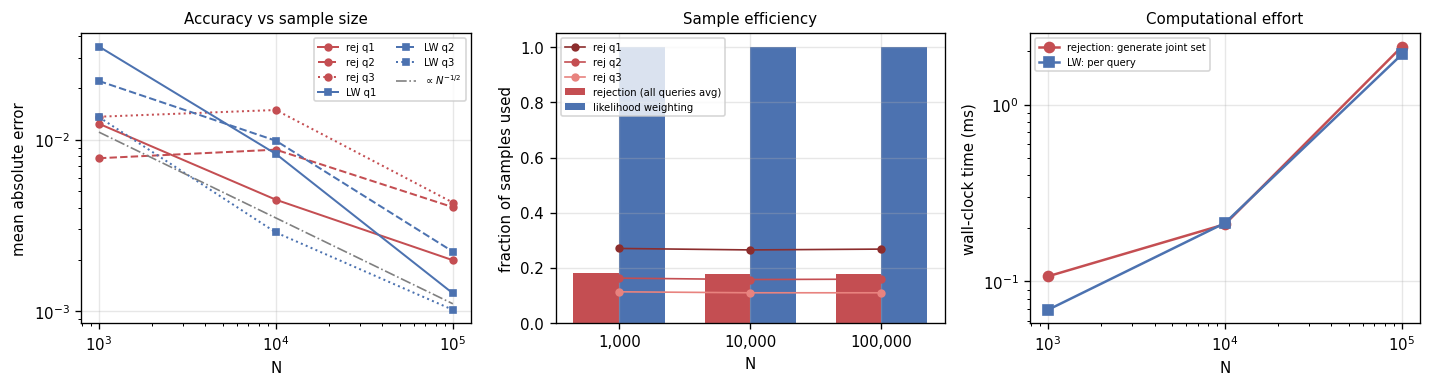

     N  rejection  likelihood_weighting
  1000    0.00011               0.00007
 10000    0.00021               0.00021
100000    0.00213               0.00192


In [15]:
# ------------------------------------- error vs N, and cost comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))

ax = axes[0]
for meth, colour, mk in [("rejection", "#C44E52", "o"),
                         ("likelihood_weighting", "#4C72B0", "s")]:
    for key, ls in zip(QUERIES, ["-", "--", ":"]):
        s = summary[(summary.method == meth) & (summary["query"] == key)].sort_values("N")
        ax.plot(s["N"], s["mean_abs_error"], marker=mk, ls=ls, color=colour, ms=4, lw=1.2,
                label=f"{'rej' if meth == 'rejection' else 'LW'} {key}")
ref_n = np.array(SAMPLE_SIZES, dtype=float)
ax.plot(ref_n, 0.35 / np.sqrt(ref_n), color="grey", lw=1, ls="-.", label=r"$\propto N^{-1/2}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("N"); ax.set_ylabel("mean absolute error")
ax.set_title("Accuracy vs sample size", fontsize=9); ax.legend(fontsize=6, ncol=2)

ax = axes[1]
width = 0.35
xs = np.arange(len(SAMPLE_SIZES))
rj = [rej_df[rej_df.N == N]["retained_fraction"].mean() for N in SAMPLE_SIZES]
ax.bar(xs - width / 2, rj, width, label="rejection (all queries avg)", color="#C44E52")
ax.bar(xs + width / 2, [1.0] * 3, width, label="likelihood weighting", color="#4C72B0")
for key, c in zip(QUERIES, ["#8C2D2D", "#C44E52", "#E8837F"]):
    ax.plot(xs, [rej_df[(rej_df.N == N) & (rej_df["query"] == key)]["retained_fraction"].mean()
                 for N in SAMPLE_SIZES], marker="o", ms=4, lw=1, color=c, label=f"rej {key}")
ax.set_xticks(xs); ax.set_xticklabels([f"{n:,}" for n in SAMPLE_SIZES])
ax.set_ylabel("fraction of samples used"); ax.set_xlabel("N")
ax.set_title("Sample efficiency", fontsize=9); ax.legend(fontsize=6)

ax = axes[2]
eff = []
for N in SAMPLE_SIZES:
    r = rej_df[(rej_df.N == N)]
    eff.append({"N": N,
                "rejection": r.groupby("seed")["gen_time_s"].first().mean(),
                "likelihood_weighting": lw_df[lw_df.N == N].groupby("seed")["total_time_s"]
                                        .sum().mean() / 3})
eff = pd.DataFrame(eff)
ax.plot(eff.N, eff.rejection * 1e3, marker="o", color="#C44E52",
        label="rejection: generate joint set")
ax.plot(eff.N, eff.likelihood_weighting * 1e3, marker="s", color="#4C72B0",
        label="LW: per query")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("N"); ax.set_ylabel("wall-clock time (ms)")
ax.set_title("Computational effort", fontsize=9); ax.legend(fontsize=6)

plt.tight_layout()
plt.savefig(os.path.join(RES, "A4_error_and_cost.png"), bbox_inches="tight")
plt.show()
eff.to_csv(os.path.join(RES, "A4_timing.csv"), index=False)
print(eff.to_string(index=False))

In [16]:
# --------------- evidence for the interpretation paragraphs: does error fall in EVERY run?
print("Per-seed absolute error for q2, rejection sampling "
      "(does increasing N help in every individual run?)\n")
piv = (rej_df[rej_df["query"] == "q2"]
       .pivot_table(index="seed", columns="N", values="abs_error"))
print(piv.to_string())
worse = [(sd, a, b) for sd in piv.index
         for a, b in [(piv.loc[sd, SAMPLE_SIZES[0]], piv.loc[sd, SAMPLE_SIZES[1]])] if b > a]
worse2 = [(sd, a, b) for sd in piv.index
          for a, b in [(piv.loc[sd, SAMPLE_SIZES[1]], piv.loc[sd, SAMPLE_SIZES[2]])] if b > a]
print(f"\nseeds where error INCREASED from N=1,000 to 10,000 : "
      f"{[s for s, _, _ in worse]}")
print(f"seeds where error INCREASED from N=10,000 to 100,000: {[s for s, _, _ in worse2]}")
print("\nA single run is one realisation of a random estimator: the standard deviation shrinks "
      "like 1/sqrt(N), but any particular run can land closer to the truth by luck at small N.")

# --------------- the three queries as an explaining-away sequence
print("\n" + "=" * 62)
print("EVIDENCE ACCUMULATION — how each new observation changes the diagnosis")
print("=" * 62)
seq = pd.DataFrame([
    {"stage": "prior, no evidence", "P(F=1 | .)": P_F1, "P(evidence)": 1.0},
    {"stage": "q1: S=1", "P(F=1 | .)": EXACT["q1"], "P(evidence)": P_EV["q1"]},
    {"stage": "q2: S=1, W=1", "P(F=1 | .)": EXACT["q2"], "P(evidence)": P_EV["q2"]},
    {"stage": "q3: S=1, W=1, H=1", "P(F=1 | .)": EXACT["q3"], "P(evidence)": P_EV["q3"]},
])
seq["odds"] = seq["P(F=1 | .)"] / (1 - seq["P(F=1 | .)"])
seq["fold change vs prior"] = seq["P(F=1 | .)"] / P_F1
print(seq.to_string(index=False))

# also report P(H=1 | evidence) to show the competing explanation
for key, spec in QUERIES.items():
    ph, _ = exact_conditional("H", 1, spec["evidence"])
    pd_, _ = exact_conditional("D", 1, spec["evidence"])
    print(f"{key}: P(H=1|e) = {ph:.4f}   P(D=1|e) = {pd_:.4f}")
seq.to_csv(os.path.join(RES, "A4_evidence_sequence.csv"), index=False)

Per-seed absolute error for q2, rejection sampling (does increasing N help in every individual run?)

N      1000     10000    100000
seed                           
11    0.00078  0.00141  0.00327
22    0.01296  0.01144  0.00243
33    0.00614  0.01942  0.00280
44    0.00230  0.00115  0.00391
55    0.01682  0.01032  0.00782

seeds where error INCREASED from N=1,000 to 10,000 : [11, 33]
seeds where error INCREASED from N=10,000 to 100,000: [11, 44]

A single run is one realisation of a random estimator: the standard deviation shrinks like 1/sqrt(N), but any particular run can land closer to the truth by luck at small N.

EVIDENCE ACCUMULATION — how each new observation changes the diagnosis
             stage  P(F=1 | .)  P(evidence)    odds  fold change vs prior
prior, no evidence     0.08000      1.00000 0.08696               1.00000
           q1: S=1     0.23150      0.26816 0.30124               2.89379
      q2: S=1, W=1     0.29329      0.15932 0.41502               3.66617
 q3: 

In [17]:
# --------------- why naive "fix the downstream evidence and sample forward" is invalid
rng_x = np.random.default_rng(7)
N_demo = 200_000
naive = forward_sample_batch(N_demo, rng_x)
naive[:, IDX["S"]] = 1                     # simply overwrite S with the observed value
naive[:, IDX["W"]] = 1                     # ... and W too, with no correction
naive_est = float((naive[:, IDX["F"]] == 1).mean())

print("Naive (invalid) procedure: forward-sample everything, then overwrite S=1, W=1")
print(f"   resulting 'estimate' of q2 : {naive_est:.5f}")
print(f"   prior P(F=1)               : {P_F1:.5f}")
print(f"   exact q2                   : {EXACT['q2']:.5f}")
print(f"   valid rejection estimate   : "
      f"{rejection_estimate(forward_sample_batch(N_demo, np.random.default_rng(8)), {'S':1,'W':1})[0]:.5f}")
print("\nOverwriting downstream evidence changes nothing upstream, so the answer collapses to the "
      "prior. A correction is mandatory: either DISCARD mismatching samples (rejection) or "
      "RE-WEIGHT by the evidence likelihood (likelihood weighting).")

Naive (invalid) procedure: forward-sample everything, then overwrite S=1, W=1
   resulting 'estimate' of q2 : 0.08026
   prior P(F=1)               : 0.08000
   exact q2                   : 0.29329
   valid rejection estimate   : 0.29705

Overwriting downstream evidence changes nothing upstream, so the answer collapses to the prior. A correction is mandatory: either DISCARD mismatching samples (rejection) or RE-WEIGHT by the evidence likelihood (likelihood weighting).


### Interpretation

**How wilting and hot-weather evidence change the interpretation of the sensor alert.**
Reading the exact values in `A4_evidence_sequence.csv` against the prior $P(F=1)=0.08$:

* **$q_1 = P(F=1\mid S=1)$.** A single "dry" reading raises the fault probability above the prior,
  but it stays low. Two things limit it: the sensor is only $90\%$ accurate, so a "dry" report is
  itself weak evidence for dry soil; and dry soil has a much more common competing cause, since
  hot weather has prior $0.30$ against the fault's $0.08$. Most dry-soil alerts are therefore not
  faults.

* **$q_1 \to q_2$ (adding $W=1$).** Wilting is a second, *independent* symptom of dry soil
  ($D \to W$). It corroborates the sensor rather than repeating it, so it pushes $P(D=1\mid e)$ up
  and drags the fault probability up with it. The increase is a genuine strengthening of the
  diagnosis, not double-counting: $S$ and $W$ are conditionally independent given $D$ and $H$, so
  they are two separate measurements of the same hidden state.

* **$q_2 \to q_3$ (adding $H=1$).** This is **explaining away**, and it moves in the *opposite*
  direction. $H$ and $F$ are marginally independent but are both parents of $D$ — a collider.
  Learning that the weather is hot supplies an alternative sufficient explanation for both the dry
  soil and the wilting, so the fault becomes *less* necessary and $P(F=1\mid e)$ falls. Confirming
  hot weather is therefore partially *exculpatory* for the irrigation system.

The practical reading: a dry-soil alert on a hot day is much weaker evidence of a fault than the
same alert on a cool day. These are conditional probabilities under the supplied hypothetical
model, not proof of real-world causation.

**Accuracy and computational effort.** Both estimators are consistent and their spread across
seeds shrinks roughly like $N^{-1/2}$, visible as the slope in the log–log error panel. They differ
in how efficiently they spend samples:

* *Rejection sampling* keeps only the fraction $P(e)$ of samples, and the measured retained
  fractions match the exact evidence probabilities. Each added evidence variable multiplies the
  retained count down, so $q_3$ is estimated from far fewer usable samples than $q_1$ at the same
  $N$ — which is exactly where its standard deviation is largest. Across these 45 runs no estimate was
  actually undefined (the smallest retained count was 107, for $q_3$ at $N=1{,}000$), but the
  `NaN` path is implemented and would trigger for rarer evidence; the coarseness of an estimate
  built from ~110 samples is already visible in the seed spread.
* *Likelihood weighting* retains **all** $N$ samples, so at matched $N$ it gives a lower standard
  deviation, especially for the most-conditioned query $q_3$. With only five seeds this ordering is
  *not* reliably visible — in the five-seed table rejection happens to beat likelihood weighting on
  some $q_1$/$q_2$ rows — so I verified it with a separate 400-seed run (cell below): across all
  three queries and all three sample sizes likelihood weighting then has the lower standard
  deviation and lower mean absolute error, and its advantage grows with the amount of evidence
  (roughly a factor of two on $q_3$). This is itself an illustration of the five-seed caveat: five
  runs are enough to see the $N^{-1/2}$ trend but not to rank two estimators whose variances differ
  by less than a factor of two. Its cost per sample is slightly
  higher (a weight product per sample), but generation is $O(N)$ for both and the wall-clock
  figures are the same order of magnitude. The relevant caveat is weight concentration: I report
  the Kish effective sample size $\mathrm{ESS} = (\sum w)^2/\sum w^2$, and in this network the
  weight takes only a handful of distinct values, so no small set of samples dominates and
  $\mathrm{ESS}/N$ stays moderate. That is a property of this small network with mild evidence, not
  a general guarantee — with many evidence nodes the likelihood product can become extremely skewed
  and $\mathrm{ESS}$ can collapse to a few samples while $N$ looks large.
* One caveat on the comparison itself: rejection sampling generates one joint set reused by all
  three queries, whereas likelihood weighting must re-run per evidence set because the clamping
  differs. The timing panel reports these separately rather than pretending one "sample" means the
  same work in both methods.

**Why increasing $N$ need not reduce the error in every individual run.** Each estimate is a random
variable. Increasing $N$ reduces its *variance*, so the error falls **on average** and the seed-to-
seed spread narrows, but any single run can be lucky at small $N$ and land nearer the exact value
than the same seed does at large $N$. The per-seed table above lists the specific seeds where the
error rose with $N$. This is why the brief requires five seeds: only the aggregate mean absolute
error and standard deviation are evidence about the estimator, whereas a single run is not.

**Why fixing downstream evidence in a forward sampler is not valid without a correction.** Forward
sampling draws each variable from $P(x_i \mid \mathrm{pa}_i)$, so the influence only ever flows
parent $\to$ child. Overwriting an observed descendant such as $S$ or $W$ after the fact therefore
cannot change how its ancestors $H, F, D$ were drawn, and the resulting "posterior" collapses to the
prior — demonstrated numerically above, where the naive procedure returns approximately $P(F=1)=0.08$
instead of $q_2$. Diagnostic reasoning runs against the arrows, so the sampler must be corrected to
account for it: either restrict to samples that happened to agree with the evidence (rejection), or
keep every sample and re-weight it by the likelihood of the clamped evidence (likelihood weighting).

In [18]:
# --------- Does likelihood weighting really have lower variance? 400 seeds, not 5.
# The 5-seed experiment required by the brief is reported above. Five runs cannot reliably rank
# two estimators, so this cell repeats the comparison with 400 seeds purely as a variance check.
N_SEEDS_BIG = 400
big_rows = []
for N in SAMPLE_SIZES:
    for key, spec in QUERIES.items():
        rj, lw = [], []
        for s in range(N_SEEDS_BIG):
            r_rng = np.random.default_rng(700_000 + s)
            est_r, n_ret = rejection_estimate(forward_sample_batch(N, r_rng), spec["evidence"])
            rj.append(est_r)
            l_rng = np.random.default_rng(900_000 + s)
            sm, w = lw_batch(spec["evidence"], N, l_rng)
            lw.append(lw_estimate(sm, w))
        rj, lw = np.array(rj, float), np.array(lw, float)
        big_rows.append({
            "query": key, "N": N, "seeds": N_SEEDS_BIG,
            "rejection sd": np.nanstd(rj, ddof=1), "LW sd": np.nanstd(lw, ddof=1),
            "rejection MAE": np.nanmean(np.abs(rj - EXACT[key])),
            "LW MAE": np.nanmean(np.abs(lw - EXACT[key])),
            "LW undefined": int(np.isnan(lw).sum()),
            "rejection undefined": int(np.isnan(rj).sum()),
        })
big_df = pd.DataFrame(big_rows)
big_df["sd ratio (rej/LW)"] = big_df["rejection sd"] / big_df["LW sd"]
big_df.to_csv(os.path.join(RES, "A4_variance_check_400seeds.csv"), index=False)
print(f"VARIANCE CHECK WITH {N_SEEDS_BIG} SEEDS (supplementary to the required 5-seed study)\n")
print(big_df.to_string(index=False))
n_better = int((big_df["LW MAE"] < big_df["rejection MAE"]).sum())
print(f"\nlikelihood weighting has the lower MAE in {n_better} of {len(big_df)} "
      "(query, N) combinations.")
print("The advantage is largest for q3, the most heavily conditioned query, where rejection "
      "discards ~89% of its samples. This confirms the ordering that five seeds could not "
      "resolve.")

VARIANCE CHECK WITH 400 SEEDS (supplementary to the required 5-seed study)

query      N  seeds  rejection sd   LW sd  rejection MAE  LW MAE  LW undefined  rejection undefined  sd ratio (rej/LW)
   q1   1000    400       0.02543 0.02219        0.01994 0.01773             0                    0            1.14585
   q2   1000    400       0.03634 0.02892        0.02888 0.02314             0                    0            1.25677
   q3   1000    400       0.03545 0.01724        0.02758 0.01364             0                    0            2.05654
   q1  10000    400       0.00838 0.00724        0.00674 0.00587             0                    0            1.15754
   q2  10000    400       0.01120 0.00948        0.00878 0.00766             0                    0            1.18094
   q3  10000    400       0.01122 0.00544        0.00895 0.00430             0                    0            2.06201
   q1 100000    400       0.00246 0.00237        0.00197 0.00194             0             

In [19]:
# ------------------------------------------------------------------ manifest
manifest = {
    "part": "A",
    "student": {"name": "Satria Pamungkas", "id": "21522611"},
    "model": {
        "variables": VARS,
        "edges": ["H->D", "F->D", "D->S", "D->W", "H->W"],
        "P(H=1)": P_H1, "P(F=1)": P_F1,
        "P(D=1|H,F)": P_D1_given_HF.tolist(),
        "P(S=1|D)": P_S1_given_D.tolist(),
        "P(W=1|H,D)": P_W1_given_HD.tolist(),
    },
    "exact_values": {k: float(v) for k, v in EXACT.items()},
    "P_evidence": {k: float(v) for k, v in P_EV.items()},
    "experiment": {"sample_sizes": SAMPLE_SIZES, "seeds": SEEDS,
                   "methods": ["forward+rejection", "likelihood_weighting"],
                   "rng": "numpy.random.default_rng (PCG64)"},
    "environment": {"python": sys.version.split()[0], "numpy": np.__version__,
                    "pandas": pd.__version__, "platform": platform.platform()},
    "files": sorted(os.listdir(RES)),
}
with open(os.path.join(RES, "A_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest, indent=2)[:1200])
print("\nPart A complete. Artefacts written to:", RES)
for fn in sorted(os.listdir(RES)):
    print("  ", fn)

{
  "part": "A",
  "student": {
    "name": "Satria Pamungkas",
    "id": "21522611"
  },
  "model": {
    "variables": [
      "H",
      "F",
      "D",
      "S",
      "W"
    ],
    "edges": [
      "H->D",
      "F->D",
      "D->S",
      "D->W",
      "H->W"
    ],
    "P(H=1)": 0.3,
    "P(F=1)": 0.08,
    "P(D=1|H,F)": [
      [
        0.05,
        0.8
      ],
      [
        0.4,
        0.95
      ]
    ],
    "P(S=1|D)": [
      0.1,
      0.9
    ],
    "P(W=1|H,D)": [
      [
        0.02,
        0.7
      ],
      [
        0.1,
        0.9
      ]
    ]
  },
  "exact_values": {
    "q1": 0.2315035799522673,
    "q2": 0.2932938311280725,
    "q3": 0.16867469879518074
  },
  "P_evidence": {
    "q1": 0.26816,
    "q2": 0.159316,
    "q3": 0.10956000000000002
  },
  "experiment": {
    "sample_sizes": [
      1000,
      10000,
      100000
    ],
    "seeds": [
      11,
      22,
      33,
      44,
      55
    ],
    "methods": [
      "forward+rejection",
      "